# Image Processing Lab – Lab 1 & Lab 2 Assignment
**Course:** Image Processing using Python and OpenCV  


## Setup – Import required libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print('OpenCV version:', cv2.__version__)

OpenCV version: 5.0.0


## Question 1 – Read `flower.jpg` using OpenCV and display it in a window titled “Original Image”.

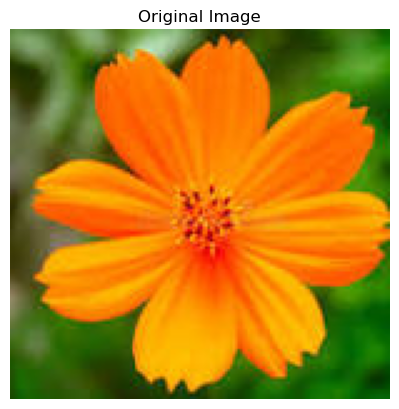

In [2]:
image_path = 'flower.jpg'
image = cv2.imread(f'flower.jpg')

if image is None:
    raise FileNotFoundError(f'Could not find or open {f'flower.jpg'}. Place it in the notebook folder.')

# OpenCV loads images in BGR order; convert to RGB for Matplotlib display.
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.title('Original Image')
plt.axis('off')
plt.show()

## Question 2 – Print the dimensions (height, width, channels) and data type of `scene.jpg`.

In [3]:
image_path = 'scene.jpg'
image = cv2.imread(f'scene.jpg')

if image is None:
    raise FileNotFoundError(f'Could not find or open {f'scene.jpg'}. Place it in the notebook folder.')

height, width = image.shape[:2]
channels = 1 if image.ndim == 2 else image.shape[2]
print('Height:', height)
print('Width:', width)
print('Channels:', channels)
print('Data type:', image.dtype)
print('Full shape:', image.shape)

Height: 148
Width: 256
Channels: 3
Data type: uint8
Full shape: (148, 256, 3)


## Question 3 – Load a colour image, convert it into a grayscale image, and save the result as `output_gray.jpg`.

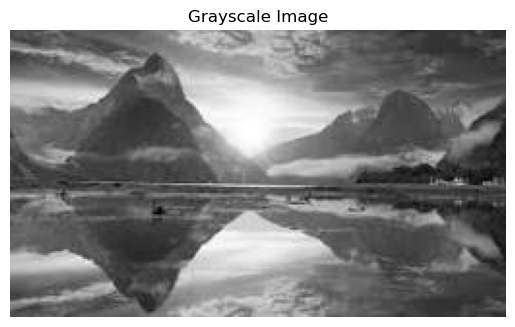

Grayscale image saved as output_gray.jpg


In [4]:
# Use scene.jpg as the input colour image for this task.
input_path = 'scene.jpg'
output_path = 'output_gray.jpg'
image = cv2.imread(input_path)

if image is None:
    raise FileNotFoundError(f'Could not find or open {input_path}. Place it in the notebook folder.')

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
saved = cv2.imwrite(output_path, gray_image)
if not saved:
    raise OSError(f'Could not save {output_path}. Check the folder permissions.')

plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()
print(f'Grayscale image saved as {output_path}')

## Question 4 – Write a short program to open `sunset.png` using Pillow and display it.

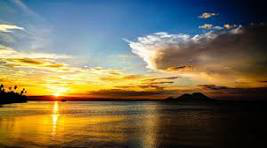

In [6]:
image_path = 'sunset.png'
try:
    with Image.open(f'sunset.jpg') as image:
        display(image.copy())
except FileNotFoundError:
    raise FileNotFoundError(f'Could not find {f'sunset.jpg'}. Place it in the notebook folder.')

## Question 5 – Resize an image to 50% of its original width and height using OpenCV.

Original dimensions (width, height): (267, 148)
Resized dimensions (width, height): (133, 74)


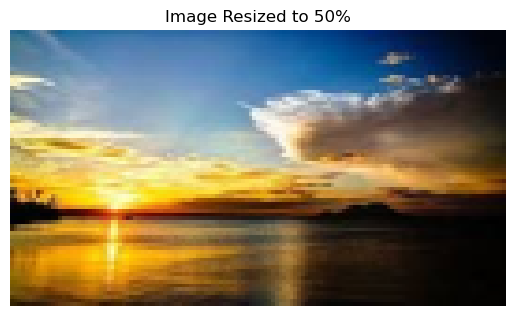

In [7]:
image_path = 'sunset.png'
image = cv2.imread(f'sunset.jpg')

if image is None:
    raise FileNotFoundError(f'Could not find or open {f'sunset.jpg'}. Place it in the notebook folder.')

height, width = image.shape[:2]
new_width = max(1, int(width * 0.5))
new_height = max(1, int(height * 0.5))
resized_image = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)

print('Original dimensions (width, height):', (width, height))
print('Resized dimensions (width, height):', (new_width, new_height))
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title('Image Resized to 50%')
plt.axis('off')
plt.show()

## Question 6 – Crop the central 200×200 pixel area of an image and display it using Matplotlib.

Original dimensions: 256 x 148


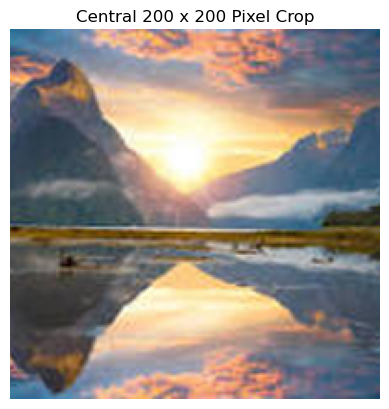

Cropped image shape: (200, 200, 3)


In [18]:
image_path = 'scene.jpg'
image = cv2.imread(f'scene.jpg')

if image is None:
    raise FileNotFoundError('Could not find scene.jpg')

height, width = image.shape[:2]

print('Original dimensions:', width, 'x', height)
scale = max(1.0, 200 / width, 200 / height)

if scale > 1:
    new_width = int(width * scale)
    new_height = int(height * scale)

    image = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_CUBIC
    )

height, width = image.shape[:2]

# Calculate central crop coordinates
start_x = (width - 200) // 2
start_y = (height - 200) // 2

# Crop central 200x200 area
cropped_image = image[
    start_y:start_y + 200,
    start_x:start_x + 200
]

# Display cropped image
plt.imshow(cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB))
plt.title('Central 200 x 200 Pixel Crop')
plt.axis('off')
plt.show()

print('Cropped image shape:', cropped_image.shape)

## Question 7 – Rotate an image by 90 degrees clockwise using OpenCV.

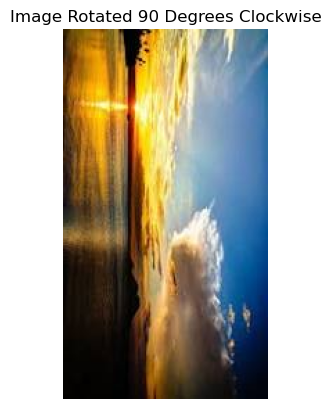

In [12]:
image_path = 'sunset.png'
image = cv2.imread(f'sunset.jpg')

if image is None:
    raise FileNotFoundError(f'Could not find or open {f'sunset.jpg'}. Place it in the notebook folder.')

rotated_image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
plt.imshow(cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB))
plt.title('Image Rotated 90 Degrees Clockwise')
plt.axis('off')
plt.show()

## Question 8 – Flip `car.jpg` from left to right using OpenCV and display the result.

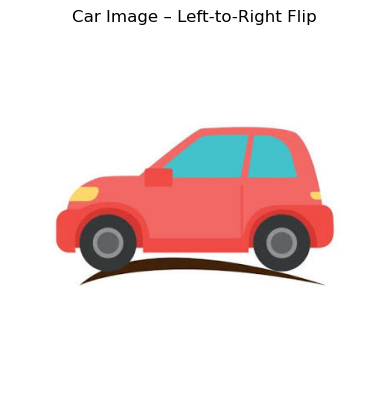

In [13]:
image_path = 'car.jpg'
image = cv2.imread(f'car.jpg')

if image is None:
    raise FileNotFoundError(f'Could not find or open {f'car.jpg'}. Place it in the notebook folder.')

# flipCode = 1 performs a horizontal (left-to-right) flip.
flipped_image = cv2.flip(image, 1)
plt.imshow(cv2.cvtColor(flipped_image, cv2.COLOR_BGR2RGB))
plt.title('Car Image – Left-to-Right Flip')
plt.axis('off')
plt.show()

## Question 9 – Convert an image from RGB to HSV colour space and display the Hue, Saturation, and Value channels separately.

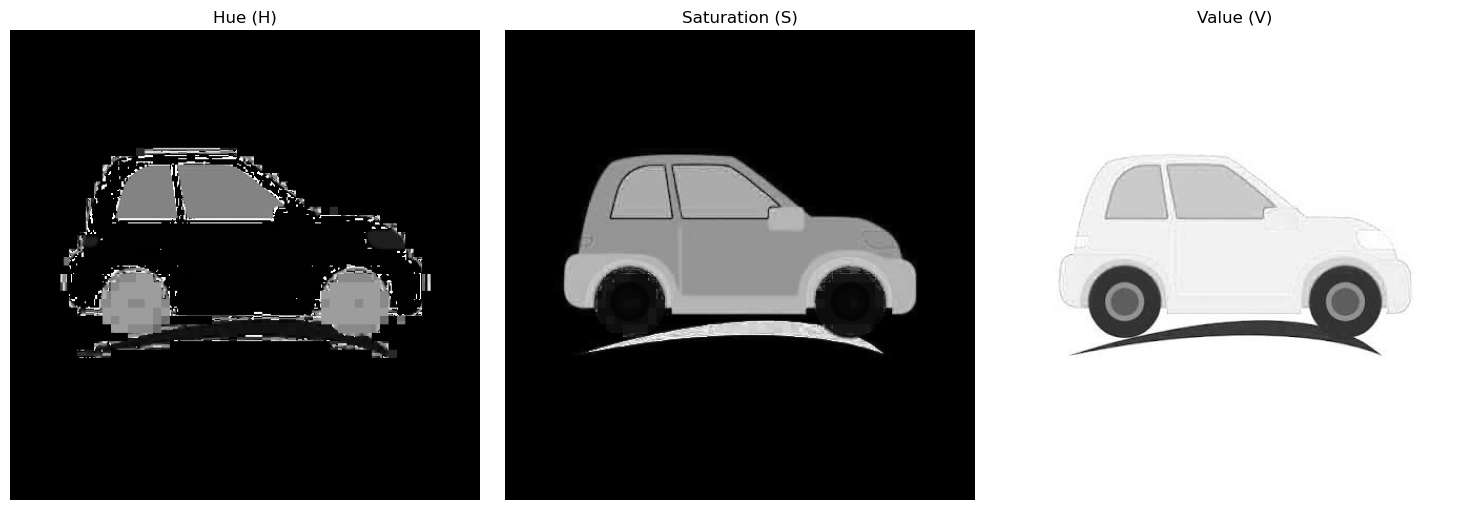

In [14]:
image_path = 'car.jpg'
image_bgr = cv2.imread(f'car.jpg')

if image_bgr is None:
    raise FileNotFoundError(f'Could not find or open {f'car.jpg'}. Place it in the notebook folder.')

# Convert BGR (OpenCV's loading format) to RGB, then RGB to HSV.
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
hue, saturation, value = cv2.split(image_hsv)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hue, cmap='gray')
axes[0].set_title('Hue (H)')
axes[1].imshow(saturation, cmap='gray')
axes[1].set_title('Saturation (S)')
axes[2].imshow(value, cmap='gray')
axes[2].set_title('Value (V)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Question 10 – Write a short Python code snippet to compute the Mean Squared Error (MSE) between `img1.jpg` and `img2.jpg`.

In [21]:
# Question 10: Calculate Mean Squared Error (MSE)

def calculate_mse(image_a, image_b):
    """Calculate Mean Squared Error between two images."""

    if image_a.shape != image_b.shape:
        raise ValueError('Images must have the same dimensions.')

    difference = image_a.astype(np.float64) - image_b.astype(np.float64)

    return np.mean(difference ** 2)


# Load two images
image1_path = 'sunset.png'
image2_path = 'scene.jpg'

image1 = cv2.imread('sunset.jpg', cv2.IMREAD_GRAYSCALE)
image2 = cv2.imread('scene.jpg', cv2.IMREAD_GRAYSCALE)


# Check images
if image1 is None:
    raise FileNotFoundError(f'Could not find {image1_path}')

if image2 is None:
    raise FileNotFoundError(f'Could not find {image2_path}')


# Resize second image to match first image
image2_resized = cv2.resize(
    image2,
    (image1.shape[1], image1.shape[0])
)


# Calculate MSE
mse_value = calculate_mse(image1, image2_resized)

print('Mean Squared Error (MSE):', mse_value)

Mean Squared Error (MSE): 6099.728540338091
